# Generative adversarial networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/gan/gan-notebook.ipynb)

Companion notebook for the *Generative adversarial networks* slides. Each idea is written first by hand
with NumPy and then checked with scikit-learn, SciPy or an independent computation.

**Data:** one feature $x$; the real data is a Gaussian $p_{\text{data}} = \mathcal{N}(4, 1.25^2)$ and the noise is $z \sim \mathcal{N}(0, 1)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

RANDOM_STATE = 42
DATA_MEAN, DATA_STD = 4.0, 1.25
BATCH = 256
D_STEPS = 5
LEARNING_RATE_D = 0.5
LEARNING_RATE_G = 0.02
ROUNDS = 5000

rng = np.random.default_rng(RANDOM_STATE)

## 1. The discriminator's loss

$D$ is a yes/no classifier (real = 1, fake = 0). One real and one fake example give
$L_D = -\log D(\mathbf{x}) - \log\big(1 - D(G(\mathbf{z}))\big)$. The slide's example: $D(\mathbf{x}) = 0.9$, $D(G(\mathbf{z})) = 0.2$.

In [2]:
loss_by_hand = -np.log(0.9) - np.log(1 - 0.2)

# scikit-learn's log-loss averages over the two examples, so multiply by 2
print(f"L_D = {loss_by_hand:.3f} | same result:", np.isclose(loss_by_hand, 2 * log_loss([1, 0], [0.9, 0.2])))

L_D = 0.329 | same result: True


## 2. A discriminator and its gradient

Our $D$ is a logistic regression on $x$ and $x^2$: $D(x) = \sigma(w_1 x + w_2 x^2 + c)$ (features divided by 4 to keep them small).
Averaged over a batch, the gradient of $L_D$ is $\frac{1}{m}\sum (D - y)\,\text{features}$, as in logistic regression.

In [3]:
def sigmoid(a: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-a))


def features(x: np.ndarray) -> np.ndarray:
    return np.column_stack([x / 4, (x / 4) ** 2])


def discriminator_loss(w: np.ndarray, c: float, x_real: np.ndarray, x_fake: np.ndarray) -> float:
    return -np.mean(np.log(sigmoid(features(x_real) @ w + c))) - np.mean(np.log(1 - sigmoid(features(x_fake) @ w + c)))


def discriminator_gradient(w: np.ndarray, c: float, x_real: np.ndarray, x_fake: np.ndarray) -> tuple[np.ndarray, float]:
    error_real = sigmoid(features(x_real) @ w + c) - 1
    error_fake = sigmoid(features(x_fake) @ w + c)
    grad_w = features(x_real).T @ error_real / len(x_real) + features(x_fake).T @ error_fake / len(x_fake)
    return grad_w, error_real.mean() + error_fake.mean()


x_real, x_fake = rng.normal(DATA_MEAN, DATA_STD, BATCH), rng.normal(0, 1, BATCH)
w, c = np.array([0.3, -0.2]), 0.1
grad_w, _ = discriminator_gradient(w, c, x_real, x_fake)

Independent check: finite differences, nudging each weight by a tiny $\varepsilon$.

In [4]:
eps = 1e-6
numeric = [(discriminator_loss(w + eps * e, c, x_real, x_fake) - discriminator_loss(w - eps * e, c, x_real, x_fake)) / (2 * eps)
           for e in np.eye(2)]
print("same result:", np.allclose(grad_w, numeric))

same result: True


## 3. The best discriminator

For a fixed $G$, $D^*(x) = \dfrac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_G(x)}$.
Here the fakes follow $p_G = \mathcal{N}(3, 1.2^2)$. Independent check: fit a logistic regression on many real and fake samples.

same result (tolerance 0.02): True


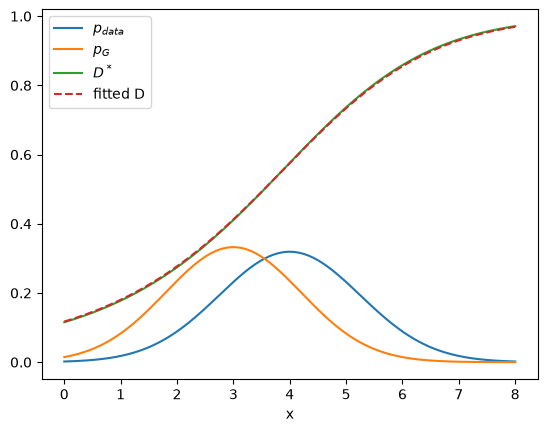

In [5]:
grid = np.linspace(0, 8, 200)
d_star = norm.pdf(grid, DATA_MEAN, DATA_STD) / (norm.pdf(grid, DATA_MEAN, DATA_STD) + norm.pdf(grid, 3, 1.2))

samples = np.concatenate([rng.normal(DATA_MEAN, DATA_STD, 100_000), rng.normal(3, 1.2, 100_000)])
is_real = np.repeat([1, 0], 100_000)
classifier = LogisticRegression(C=1e6, max_iter=1000).fit(features(samples), is_real)
d_fitted = classifier.predict_proba(features(grid))[:, 1]
print("same result (tolerance 0.02):", np.allclose(d_star, d_fitted, atol=0.02))

plt.plot(grid, norm.pdf(grid, DATA_MEAN, DATA_STD), label="$p_{data}$")
plt.plot(grid, norm.pdf(grid, 3, 1.2), label="$p_G$")
plt.plot(grid, d_star, label="$D^*$")
plt.plot(grid, d_fitted, linestyle="--", label="fitted D")
plt.xlabel("x")
plt.legend()
plt.show()

When $p_G = p_{\text{data}}$, $D^* = \tfrac12$ everywhere and $V = \log\tfrac12 + \log\tfrac12 = -\log 4$.

In [6]:
x = rng.normal(DATA_MEAN, DATA_STD, 10)
d_star_equal = norm.pdf(x, DATA_MEAN, DATA_STD) / (2 * norm.pdf(x, DATA_MEAN, DATA_STD))
print("same result:", np.allclose(d_star_equal, 0.5) and np.isclose(2 * np.log(0.5), -np.log(4)))

same result: True


## 4. Training in turns

The generator is $G(z) = a z + b$. Each round: `D_STEPS` steps of gradient descent on $L_D$, then one step for $G$ on the
non-saturating loss $L_G = -\log D(G(z))$. By the chain rule, $\dfrac{\partial L_G}{\partial G(z)} = -(1 - D)\,\dfrac{\partial s}{\partial x}$, where $s$ is $D$'s score.

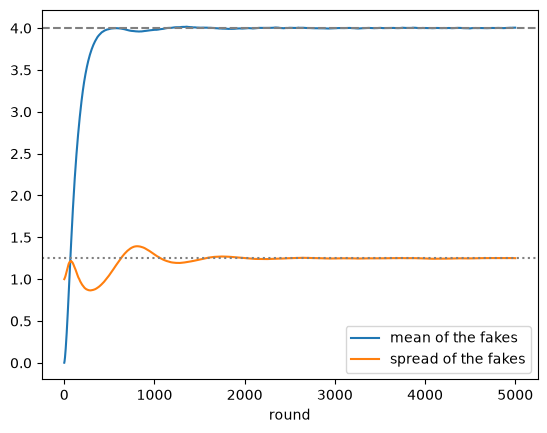

In [7]:
a, b = 1.0, 0.0
w, c = np.zeros(2), 0.0
history = []
for _ in range(ROUNDS):
    for _ in range(D_STEPS):
        x_real, x_fake = rng.normal(DATA_MEAN, DATA_STD, BATCH), a * rng.normal(size=BATCH) + b
        grad_w, grad_c = discriminator_gradient(w, c, x_real, x_fake)
        w, c = w - LEARNING_RATE_D * grad_w, c - LEARNING_RATE_D * grad_c
    z = rng.normal(size=BATCH)
    x_fake = a * z + b
    d_fake = sigmoid(features(x_fake) @ w + c)
    d_score_dx = w[0] / 4 + 2 * w[1] * x_fake / 16
    grad_x = -(1 - d_fake) * d_score_dx / BATCH
    a, b = a - LEARNING_RATE_G * np.sum(grad_x * z), b - LEARNING_RATE_G * np.sum(grad_x)
    history.append((b, abs(a)))

plt.plot(np.array(history), label=["mean of the fakes", "spread of the fakes"])
plt.axhline(DATA_MEAN, color="gray", linestyle="--")
plt.axhline(DATA_STD, color="gray", linestyle=":")
plt.xlabel("round")
plt.legend()
plt.show()

The fakes' mean and spread move toward the data's. Training is noisy, so we compare with a tolerance of 0.1.

In [8]:
generated = a * rng.normal(size=100_000) + b
print(f"generated mean {generated.mean():.2f}, std {generated.std():.2f}")
print("close to the data (tolerance 0.1):",
      np.isclose(generated.mean(), DATA_MEAN, atol=0.1) and np.isclose(generated.std(), DATA_STD, atol=0.1))

generated mean 4.01, std 1.25
close to the data (tolerance 0.1): True


## Exercises

1. Replace $L_G$ in section 4 by the saturating loss $\log(1 - D(G(z)))$ and start the generator far away ($b = -5$). What changes?
2. Set `D_STEPS = 1`. Is training still as stable?
3. Remove the $x^2$ feature from $D$. Can the generator still learn the right spread? Why?